# Wrong models for transitive inference
The purpose of this notebook is to outline a variety of wrong models for computing transitive inference.

## Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import seaborn as sns

import string
from tqdm import tqdm

from relational_attention.tasks import TransitiveInferenceDataset

In [2]:
torch.manual_seed(42)

## Simple dot product

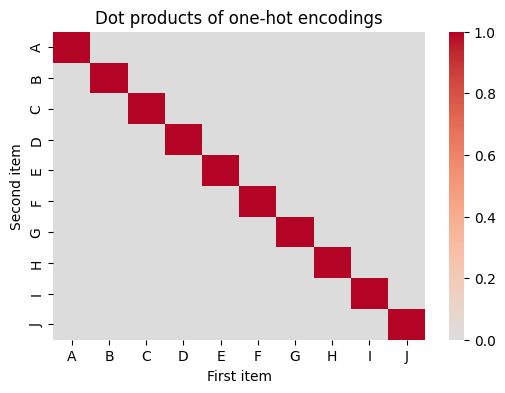

In [3]:
fig, axes = plt.subplots(1, 1, figsize=(6, 4))
sns.heatmap(np.eye(10), cmap="coolwarm", center=0, ax=axes)
axes.set_title("Dot products of one-hot encodings")
axes.set_xlabel("First item")
axes.set_ylabel("Second item")

labels = list(string.ascii_uppercase[:10])
axes.set_xticks([x+0.5 for x in range(10)])
axes.set_xticklabels(labels)
axes.set_yticks([x+0.5 for x in range(10)])
axes.set_yticklabels(labels)

plt.show()

## CoRelNet
This model uses the same matrix to encode both keys and queries.

In [4]:
class CoRelNet(nn.Module):
    def __init__(self, embed_dim, head_dim):
        super().__init__()
        # Initialize weights
        self.W = nn.Linear(embed_dim, head_dim, bias=False)

    def forward(self, x_1, x_2):
        """
        x_1: (batch, embed_dim)
        x_2: (batch, embed_dim)
        returns: (batch, seq_len, head_dim)
        """
        Q = self.W(x_2)                            # (B, D)
        K = self.W(x_1)                            # (B, D)

        # Compute attention scores over the *learned* Value slots
        attn_weights = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
        return attn_weights.flatten()

### Make task

In [5]:
# Parameters
num_samples = 1000
num_items = 10

In [6]:
# Training task
dataset = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items, train=False, all=True)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [7]:
dataset.data[0], dataset.labels[0]

(tensor([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]]),
 tensor(1.))

### Initialize model

In [8]:
model_corelnet = CoRelNet(num_items, 10)

### Train model

In [9]:
def train_model(
    model,
    data_loader,
    optimizer=None,
    loss_fn=None,
    epochs=10,
    device=None,
    return_history=True,
    verbose=True,
):
    # Defaults
    device = device or next(model.parameters()).device
    optimizer = optimizer or torch.optim.Adam(model.parameters())
    loss_fn = loss_fn or torch.nn.BCEWithLogitsLoss()

    # Put model in training mode
    model.train()

    loss_history = []

    # Optionally wrap tqdm
    progress = range(epochs)
    if verbose:
        progress = tqdm(progress, desc="Training", total=epochs, leave=True)

    for epoch in progress:
        total_loss = 0.0

        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()

            preds = model(X[:,0:1,:], X[:,1:2,:])
            loss = loss_fn(preds, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(data_loader)
        loss_history.append(avg_loss)

        # Update progress bar if active
        if verbose:
            progress.set_postfix({"loss": f"{avg_loss:.4f}"})

    if verbose:
        progress.close()

    return loss_history if return_history else None


def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in loader:
            logits = model(X[:,0:1,:], X[:,1:2,:])
            preds = (torch.sigmoid(logits) > 0.5)

            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total

In [10]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 500

In [11]:
optimizer = torch.optim.Adam(model_corelnet.parameters(), lr=lr)
loss = train_model(model_corelnet, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 500/500 [00:09<00:00, 54.25it/s, loss=0.6802]


### Plot loss

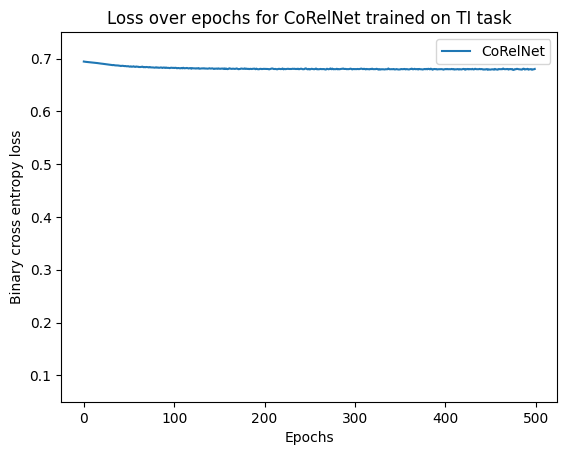

In [12]:
plt.plot(loss, label='CoRelNet')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for CoRelNet trained on TI task')
plt.ylim(0.05,0.75)
plt.legend()
plt.show()

### Plot Query-Key matrix

In [13]:
Q_weights = model_corelnet.W.weight.data
K_weights = model_corelnet.W.weight.data

In [14]:
sim_qk = (Q_weights.T @ K_weights) / (K_weights.size(-1) ** 0.5)
sim_qk.shape

torch.Size([10, 10])

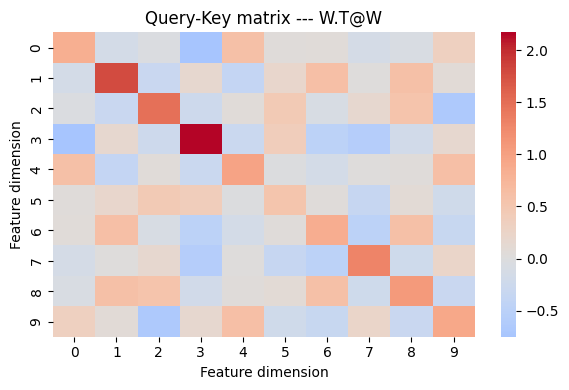

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

sns.heatmap(sim_qk, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Query-Key matrix --- W.T@W")

ax.set_xlabel("Feature dimension")
ax.set_ylabel("Feature dimension")

plt.tight_layout()
plt.show()